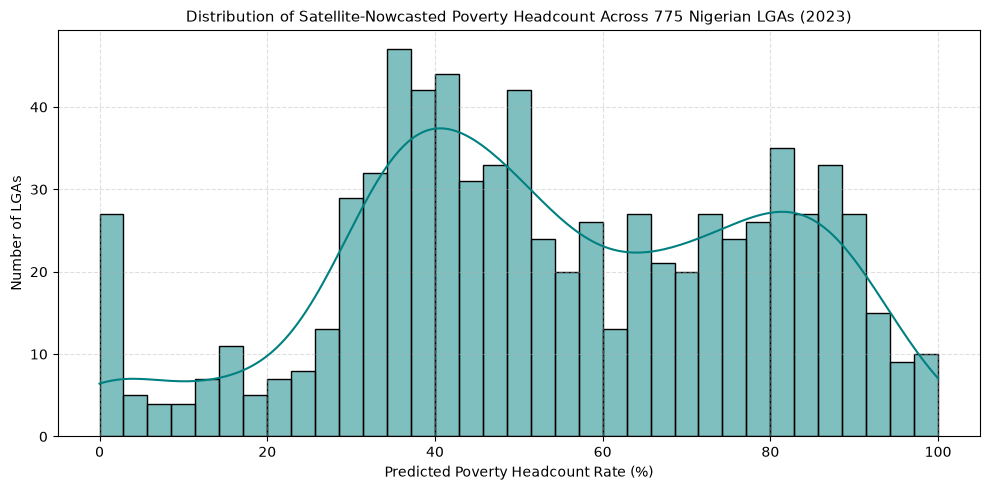

✓ Saved distribution plot to docs/lga_poverty_distribution.png


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_lga = pd.read_csv('../data/processed/nigeria_lga_poverty_nowcast_2023.csv')

plt.figure(figsize=(10, 5))
sns.histplot(df_lga['predicted_poverty_pct'], bins=35, kde=True, color='teal')
plt.title("Distribution of Satellite-Nowcasted Poverty Headcount Across 775 Nigerian LGAs (2023)", fontsize=11)
plt.xlabel("Predicted Poverty Headcount Rate (%)")
plt.ylabel("Number of LGAs")
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('../docs/lga_poverty_distribution.png', dpi=300)
plt.show()

print("✓ Saved distribution plot to docs/lga_poverty_distribution.png")

In [2]:
# Measure the gap between the poorest and wealthiest LGA within each state
disparities = df_lga.groupby('state_name')['predicted_poverty_pct'].agg(
    min_poverty='min',
    max_poverty='max',
    mean_poverty='mean',
    spread=lambda x: x.max() - x.min()
).sort_values('spread', ascending=False)

print("Top 10 States with the Highest Intra-State Inequality (LGA Spread):")
print(disparities.head(10).round(2))

Top 10 States with the Highest Intra-State Inequality (LGA Spread):
            min_poverty  max_poverty  mean_poverty  spread
state_name                                                
Kano               0.00        94.91         67.37   94.91
Kaduna             0.00        78.54         57.70   78.54
Rivers             0.00        78.08         35.96   78.08
Delta              0.00        57.14         24.76   57.14
Borno             44.96       100.00         78.99   55.04
Taraba            20.82        75.66         54.62   54.84
Oyo                6.06        60.87         43.03   54.80
Lagos              0.00        54.68         11.40   54.68
Abuja              5.21        58.56         38.92   53.35
Anambra            5.25        58.07         36.53   52.82
